
## Defining "Pop-in" Events in Nanoindentation

A **pop-in** is a sudden event during a nanoindentation test, observed as an abrupt horizontal "burst" or step in the load-displacement (P-h) curve. In this step, the indenter penetrates deeper into the material ($\Delta D \gg 0$) with little to no corresponding increase in the applied load ($\Delta F \approx 0$).

These events are not noise; they are signatures of distinct, nanoscale deformation mechanisms. Identifying and classifying them provides critical insights into the material's mechanical behavior, such as its transition from elastic to plastic deformation, the presence of internal defects, or the initiation of fracture.



### Pop-in Classification Table

Based on their signature on the load-displacement curve, pop-ins can be classified into several primary types:

| Pop-in Type | Physical Meaning | Key Characteristics (Signature) |
| :--- | :--- | :--- |
| **Primary Pop-in** | **Dislocation Nucleation:** The first burst of plastic deformation in a defect-free crystal volume. | A single, large, sharp displacement burst during the initial elastic loading portion of the curve. |
| **Serrated Flow** | **Dislocation Avalanches:** Bursts of collective dislocation motion or interaction with obstacles. | A *series* of multiple, smaller, and continuous pop-in events, typically occurring after the primary pop-in (in the plastic region). The curve looks like a staircase. |
| **Cracking Event** | **Micro-fracture:** The formation and propagation of radial or lateral micro-cracks. | A pop-in event (sudden `\Delta D`) that is immediately followed by a distinct **drop in load** (`\Delta F < 0`) as the material fails and loses load-bearing capacity. |
| **Phase Change** | **Pressure-Induced Transformation:** The material's crystal structure changes under high contact pressure. | Often a large displacement plateau during loading, but its most distinct signature is a "pop-out" (sudden displacement *recovery*) on the **unloading curve**. |

---

## Algorithm for Robust Pop-in Detection and Classification

This algorithm improves upon a simple slope threshold by using signal processing techniques to reduce noise sensitivity and by incorporating classification logic.



### 1. Pre-processing and Metric Calculation

For each indent's loading curve (from $F=0$ to $F=F_{max}$):

1.  **Smooth Data:** Apply a **Savitzky-Golay (SavGol) filter** to the `Displacement_um` and `Force_uN` data. This fits a polynomial to small windows of the data, which preserves the sharpness of pop-in events while removing high-frequency sensor noise.
2.  **Calculate Compliance Derivative ($dD/dF$):** Calculate the derivative of displacement with respect to force. A pop-in, being a horizontal step ($dF \approx 0$ and $dD > 0$), appears as a sharp **peak** ($dD/dF \to \infty$) in this signal. This is much easier to detect than the stiffness ($dF/dD$), which drops to zero.

### 2. Peak Identification (Detection)

1.  **Find Peaks:** Use a standard peak-finding algorithm (e.g., `scipy.signal.find_peaks`) on the smoothed $dD/dF$ (compliance) signal.
2.  **Filter Peaks:** Apply thresholds to the `find_peaks` function to ensure only physically significant events are captured:
    * `height`: Sets the minimum $dD/dF$ value to be considered a peak. This ignores minor material fluctuations.
    * `prominence`: Sets the minimum "vertical drop" on either side of a peak. This is the most effective parameter for rejecting false positives from noise spikes.

### 3. Event Characterization and Classification

For each peak (pop-in event) identified in Step 2:

1.  **Characterize:**
    * Find the `(F, D)` coordinates at the start of the pop-in.
    * Calculate the event magnitude: `\Delta D` (the horizontal length of the step).
    * Calculate the slope $dF/dD$ (stiffness) at the event.
    * Count the total number of peaks (`num_peaks`) found for the indent.

2.  **Classify (Apply Rules):**
    * **IF** `num_peaks == 1` and the event is the *first* peak:
        * Classify as **"Primary Pop-in (Dislocation Nucleation)"**.
    * **IF** `num_peaks > 1`:
        * Classify all events for that indent as **"Serrated Flow (Avalanches)"**.
    * **IF** the $dF/dD$ slope *during* the event is significantly **negative**:
        * Override other classifications and label as **"Probable Cracking"**.

### 4. Extension for Phase Transformation

* To detect **Phase Transformations**, run the same algorithm (Steps 1-3) on the **unloading curve** (from $F=F_{max}$ down to $F=0$).
* A peak in the $dD/dF$ signal on the *unloading* curve is a "pop-out" (displacement recovery).
* **IF** a significant pop-in is found on loading AND a significant pop-out is found on unloading:
    * Classify as **"Phase Transformation"**.

### **Data Loading and Prep**

In [ ]:
## --- 1. Setup and Imports ---
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np  # Added for numerical operations
from scipy.signal import savgol_filter  # Added for smoothing

# Set some aesthetic preferences for our plots
sns.set_theme(style="whitegrid", palette="viridis")
print("Libraries imported successfully!")


## --- 2. Loading and Cleaning Raw Data ---

# Define the column names based on your file format.
column_names = {
    0: 'Index',
    2: 'Displacement_um',
    5: 'PosX_um',
    6: 'PosY_um',
    10: 'Force_uN',
    29: 'Hardness_MPa',
    30: 'ReducedModulus_MPa'
}

# Load the data using pandas.read_csv
try:
    df = pd.read_csv('nano.txt', comment='/', delim_whitespace=True, header=None)
    
    # Keep only the columns we need and rename them
    df = df[column_names.keys()].rename(columns=column_names)

    # Convert Index to integer for cleaner grouping
    df['Index'] = df['Index'].astype(int)

    # Remove any rows with NaN (Not a Number) values which can cause errors
    df.dropna(inplace=True)
    
    # Remove initial contact points where force or displacement is negative (often noise)
    df = df[(df['Force_uN'] >= 0) & (df['Displacement_um'] >= 0)]

    print(f"Data loaded successfully!")
    print(f"Found data for {df['Index'].nunique()} unique indentation sites.")

except FileNotFoundError:
    print("Error: nano.txt not found. Please make sure it's in the same directory.")
except Exception as e:
    print(f"An error occurred: {e}")


## --- 3. Algorithm Preparation ---

print("\nStarting algorithm preparation...")

# --- Parameters for Smoothing and Calculation ---
# Window length for the Savitzky-Golay filter. Must be ODD.
# A larger number means more smoothing but can blunt sharp features.
SAVGOL_WINDOW = 11
# Polynomial order for the filter. 2 or 3 is usually good.
SAVGOL_POLY = 2
# Epsilon to prevent divide-by-zero errors
EPSILON = 1e-9

def prepare_indent_for_algo(indent_data):
    """
    Takes a DataFrame for a single indent and prepares it for pop-in analysis.
    1. Isolates the loading curve.
    2. Applies a SavGol filter to smooth the data.
    3. Calculates the compliance derivative (dD/dF) as the pop-in signal.
    """
    
    # Ensure there are enough data points for the filter window
    if indent_data.shape[0] < SAVGOL_WINDOW:
        return None
    
    # 1. Isolate the loading part of the curve (from start to max force)
    # Using idxmax() finds the *first* occurrence of the maximum force
    try:
        max_force_idx = indent_data['Force_uN'].idxmax()
        loading_data = indent_data.loc[:max_force_idx].copy()
    except ValueError:
        # Handle empty or problematic data slices
        return None

    # 2. Check if the loading curve is large enough to filter
    if loading_data.shape[0] < SAVGOL_WINDOW:
        return None

    # 3. Apply SavGol filter to smooth out noise
    loading_data['Disp_smooth'] = savgol_filter(
        loading_data['Displacement_um'], SAVGOL_WINDOW, SAVGOL_POLY
    )
    loading_data['Force_smooth'] = savgol_filter(
        loading_data['Force_uN'], SAVGOL_WINDOW, SAVGOL_POLY
    )
    
    # 4. Calculate the derivative of smoothed data
    delta_disp = np.diff(loading_data['Disp_smooth'])
    delta_force = np.diff(loading_data['Force_smooth'])

    # 5. Calculate compliance derivative (dD/dF) as the pop-in signal
    # A pop-in (horizontal step) will be a large peak in this signal.
    dD_dF = delta_disp / (delta_force + EPSILON)
    
    # Pad the derivative array (which is 1 element shorter) to match the DataFrame
    loading_data['dD_dF'] = np.insert(dD_dF, 0, 0)
    
    # Clean up any potential inf/-inf values that may have occurred
    loading_data['dD_dF'].replace([np.inf, -np.inf], 0, inplace=True)
    
    return loading_data

# --- Process all indents ---
print("Grouping data by indent and applying preparation function...")

# Group by 'Index'
grouped_indents = df.groupby('Index')

# Apply the preparation function to each group
# This creates a list of DataFrames, one for each prepared indent
prepared_data_list = [prepare_indent_for_algo(group) for _, group in grouped_indents]

# Filter out any 'None' results from indents that were too small to process
prepared_data_list = [df_item for df_item in prepared_data_list if df_item is not None]

# (Optional) Combine back into one large DataFrame for some types of analysis
prepared_df = pd.concat(prepared_data_list)

print(f"Successfully processed and prepared {len(prepared_data_list)} indents.")
print("\nData is now ready for the pop-in detection algorithm.")
print("--- Example of Prepared Data (Indent #1) ---")
# Display the new columns for the first indent
print(prepared_data_list[0].head())

Libraries imported successfully!
Data loaded successfully!
Found data for 999 unique indentation sites.

Starting algorithm preparation...
Grouping data by indent and applying preparation function...
Successfully processed and prepared 999 indents.

Data is now ready for the pop-in detection algorithm.
--- Example of Prepared Data (Indent #1) ---
    Index  Displacement_um  PosX_um   PosY_um  Force_uN  Hardness_MPa  \
1       1          0.00621 -825.956  5583.943   0.24569       0.00050   
10      1          0.00585 -825.956  5583.943   0.10456       0.00043   
15      1          0.00569 -825.956  5583.943   0.10677       0.00043   
19      1          0.00591 -825.956  5583.943   0.33288       0.00063   
20      1          0.00613 -825.956  5583.943   0.56263       0.00135   

    ReducedModulus_MPa  Disp_smooth  Force_smooth     dD_dF  
1            172.36277     0.007603      0.250963  0.000000  
10            60.22389     0.005923      0.207640  0.038793  
15           205.58150    

C:\Users\Hanamanthagouda\AppData\Local\Temp\ipykernel_21168\778995462.py:29: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv('nano.txt', comment='/', delim_whitespace=True, header=None)
C:\Users\Hanamanthagouda\AppData\Local\Temp\ipykernel_21168\778995462.py:110: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  loading_data['dD_dF'].replace([np.inf, -np.inf], 0, inplace=True)
C:\Users\Hanamanthagouda\AppData\Local\Temp

In [37]:
## --- Step 4/6 (New Method): Consecutive "Flat Points" Detection ---

import numpy as np

print("--- Step 4 (New Method): Starting Consecutive 'Flat Points' Detection ---")

# --- Parameters from your code ---
SLOPE_THRESHOLD = 10  # (uN / um)
MIN_FORCE_FOR_DETECTION_uN = 25
MIN_CONSECUTIVE_POINTS = 1

# Epsilon to prevent divide-by-zero errors
EPSILON = 1e-9

# This list will store our findings
popin_analysis_results = []

# This dictionary will store the prepared loading data for Step 5
prepared_loading_data = {}

# This dictionary will store the raw indent data for Step 5
raw_indent_groups = {idx: group_df for idx, group_df in df.groupby('Index')}


# --- Loop through each indent (using the original 'df') ---
print(f"Analyzing {df['Index'].nunique()} indents...")

grouped_indents = df.groupby('Index')

for index, indent_data in grouped_indents:
    
    # 1. Isolate the loading part of the curve (from start to max force)
    try:
        max_force_idx = indent_data['Force_uN'].idxmax()
        loading_data = indent_data.loc[:max_force_idx].copy()
    except ValueError:
        continue # Skip empty or problematic slices

    if loading_data.shape[0] < MIN_CONSECUTIVE_POINTS + 1:
        continue # Not enough data to analyze

    # 2. Calculate raw derivatives (slope dF/dD)
    delta_force = np.diff(loading_data['Force_uN'])
    delta_disp = np.diff(loading_data['Displacement_um'])
    
    # Calculate slope (dF/dD)
    slope = delta_force / (delta_disp + EPSILON)
    
    # Pad the slope array to match the dataframe (it's 1 shorter)
    slope_padded = np.insert(slope, 0, np.inf)
    loading_data['Slope_dF_dD'] = slope_padded

    # 3. Create boolean masks based on our conditions
    is_flat = loading_data['Slope_dF_dD'] < SLOPE_THRESHOLD
    is_above_min_force = loading_data['Force_uN'] > MIN_FORCE_FOR_DETECTION_uN
    
    # The final mask: points that are BOTH flat AND above the min force
    is_popin_candidate = is_flat & is_above_min_force

    # 4. Find *consecutive runs* of 'True' in the mask
    consecutive_count = 0
    peak_indices_found = [] # Store the *start* index of each pop-in event

    for i, is_candidate in enumerate(is_popin_candidate):
        if is_candidate:
            consecutive_count += 1
        else:
            # If we just finished a run...
            if consecutive_count >= MIN_CONSECUTIVE_POINTS:
                # ...log the STARTING point of this pop-in event
                start_of_event_index = loading_data.index[i - consecutive_count]
                peak_indices_found.append(start_of_event_index)
            
            # Reset the counter
            consecutive_count = 0
            
    # Check for a run that might have ended at the very last data point
    if consecutive_count >= MIN_CONSECUTIVE_POINTS:
        start_of_event_index = loading_data.index[len(loading_data) - consecutive_count]
        peak_indices_found.append(start_of_event_index)

    # 5. Store the results for this indent
    if peak_indices_found:
        popin_analysis_results.append({
            'Index': index,
            'Peak_Indices': peak_indices_found, # List of index labels (not row numbers)
            'Peak_Count': len(peak_indices_found)
        })
        # Store the loading data for Step 5
        prepared_loading_data[index] = loading_data

# --- Summary Report ---
indents_with_popins = [res for res in popin_analysis_results if res['Peak_Count'] > 0]
popin_count = len(indents_with_popins)
popin_indices_list = sorted([res['Index'] for res in indents_with_popins])

print("\n--- Consecutive Points Detection Summary ---")
print(f"Algorithm finished. (Slope < {SLOPE_THRESHOLD}, Min Force > {MIN_FORCE_FOR_DETECTION_uN}, Min Consecutive = {MIN_CONSECUTIVE_POINTS})")
print(f"Found {popin_count} indents with potential pop-in events.")
if popin_count > 0:
    print(f"Detected Indent Indices ({popin_count} total): {popin_indices_list}")
else:
    print("\nNo events found. Suggestions:")
    print(f" - Try decreasing MIN_CONSECUTIVE_POINTS (e.g., to 2)")
    print(f" - Try increasing SLOPE_THRESHOLD (e.g., to 15 or 20)")
print("-----------------------------------")
print("\nNext step: Event Characterization & Classification.")

--- Step 4 (New Method): Starting Consecutive 'Flat Points' Detection ---
Analyzing 999 indents...

--- Consecutive Points Detection Summary ---
Algorithm finished. (Slope < 10, Min Force > 25, Min Consecutive = 1)
Found 25 indents with potential pop-in events.
Detected Indent Indices (25 total): [18, 26, 63, 140, 171, 242, 342, 451, 456, 458, 513, 594, 604, 651, 658, 702, 748, 760, 771, 836, 842, 874, 916, 969, 993]
-----------------------------------

Next step: Event Characterization & Classification.


In [41]:
## --- Step 5/6 (Revised): Event Characterization & Classification ---

from scipy.signal import savgol_filter, find_peaks
import numpy as np

print("--- Step 5 (Revised): Starting Event Characterization & Classification ---")

# --- Parameters for Classification ---
# Slope threshold for detecting a "load drop" (cracking event)
CRACKING_SLOPE_THRESHOLD = -50  # (uN / um)

# Smoothing parameters
SAVGOL_WINDOW = 11
SAVGOL_POLY = 2
EPSILON = 1e-9 # From previous step

# *** NEW *** Stricter Pop-out detection parameters
# We only want to find very clear, distinct pop-out events.
POPOUT_PEAK_HEIGHT = 5.0
POPOUT_PEAK_PROMINENCE = 5.0

# This list will hold our final, detailed analysis
classified_popin_events = []

def get_unloading_popout(indent_data, peak_height, peak_prominence):
    """
    Analyzes the UNLOADING curve of a single indent to find a "pop-out".
    A pop-out is a signature of a reversible phase transformation.
    """
    if indent_data.shape[0] < SAVGOL_WINDOW:
        return []
    
    try:
        # 1. Isolate the unloading part of the curve (from max force to end)
        max_force_idx = indent_data['Force_uN'].idxmax()
        unloading_data = indent_data.loc[max_force_idx:].copy()
        
        # We need to reverse the data so displacement is "increasing" for the peak finder
        unloading_data = unloading_data.iloc[::-1]
        
    except ValueError:
        return []

    if unloading_data.shape[0] < SAVGOL_WINDOW:
        return []

    # 2. Smooth the reversed unloading data
    try:
        unloading_data['Disp_smooth'] = savgol_filter(
            unloading_data['Displacement_um'], SAVGOL_WINDOW, SAVGOL_POLY
        )
        unloading_data['Force_smooth'] = savgol_filter(
            unloading_data['Force_uN'], SAVGOL_WINDOW, SAVGOL_POLY
        )
    except ValueError:
        return []
    
    # 3. Calculate derivative (dD/dF)
    delta_disp = np.diff(unloading_data['Disp_smooth'])
    delta_force = np.diff(unloading_data['Force_smooth'])
    
    dD_dF_unload = delta_disp / (np.abs(delta_force) + EPSILON)
    
    unloading_data['dD_dF_unload'] = np.insert(dD_dF_unload, 0, 0)
    unloading_data['dD_dF_unload'].replace([np.inf, -np.inf], 0, inplace=True)

    # 4. Find peaks (which are "pop-outs" in this context)
    popout_indices, _ = find_peaks(
        unloading_data['dD_dF_unload'],
        height=peak_height,
        prominence=peak_prominence
    )
    
    return popout_indices.tolist()


# --- Loop through only the indents that had pop-ins ---
# 'indents_with_popins' was created in the previous cell (Step 4)
print(f"Classifying events for {len(indents_with_popins)} indents...")

for popin_info in indents_with_popins:
    indent_index = popin_info['Index']
    peak_count = popin_info['Peak_Count']
    
    # Get the prepared loading data (from Step 4)
    loading_data = prepared_loading_data.get(indent_index)
    # Get the raw full-indent data (from Step 4)
    raw_data = raw_indent_groups.get(indent_index)
    
    if loading_data is None or raw_data is None:
        print(f"Warning: Could not find data for Index {indent_index}. Skipping.")
        continue

    # --- Check for Phase Transformation (Pop-Out) ---
    # This check is now much stricter
    popout_indices = get_unloading_popout(raw_data, POPOUT_PEAK_HEIGHT, POPOUT_PEAK_PROMINENCE)
    
    is_phase_change = len(popout_indices) > 0
    
    # --- Classify Each Peak Found on the Loading Curve ---
    for i, peak_idx in enumerate(popin_info['Peak_Indices']):
        
        # Get data for this specific pop-in event from the loading_data
        popin_disp = loading_data.loc[peak_idx, 'Displacement_um']
        popin_force = loading_data.loc[peak_idx, 'Force_uN']
        
        # This is our dF/dD stiffness, already calculated in the loading_data
        stiffness = loading_data.loc[peak_idx, 'Slope_dF_dD']
        
        # --- *** NEW Multi-Label Classification *** ---
        event_types_list = []
        
        # 1. Base classification (Plasticity)
        if peak_count == 1:
            event_types_list.append("Primary Pop-in")
        else:
            event_types_list.append("Serrated Flow")

        # 2. Check for Cracking
        if stiffness < CRACKING_SLOPE_THRESHOLD:
            event_types_list.append("Probable Cracking")
            
        # 3. Check for Phase Change
        if is_phase_change:
            # We only add this tag to the *first* pop-in event
            if i == 0:
                event_types_list.append("Phase Transformation")

        # Store the detailed results
        classified_popin_events.append({
            'Index': indent_index,
            'Event_Type_List': event_types_list,
            'Event_Type_Str': ", ".join(event_types_list), # For easier reading
            'Event_Num': i + 1,
            'Total_Events': peak_count,
            'Popin_Force_uN': popin_force,
            'Popin_Disp_um': popin_disp,
            'Stiffness_dF_dD': stiffness,
            'Has_PopOut': is_phase_change
        })

# --- Convert final results to a DataFrame for easy reporting ---
classified_df = pd.DataFrame(classified_popin_events)

print("Classification complete.")
if not classified_df.empty:
    print("\n--- Classification Results Sample ---")
    print(classified_df.head())
    
    print("\n--- Event Type Summary ---")
    # We now count the combined string labels
    print(classified_df['Event_Type_Str'].value_counts())
else:
    print("No events were classified.")

print("\nNext step: Final Report and Visualization.")

--- Step 5 (Revised): Starting Event Characterization & Classification ---
Classifying events for 25 indents...
Classification complete.

--- Classification Results Sample ---
   Index                                    Event_Type_List  \
0     18  [Primary Pop-in, Probable Cracking, Phase Tran...   
1     26                [Primary Pop-in, Probable Cracking]   
2     63  [Primary Pop-in, Probable Cracking, Phase Tran...   
3    140  [Primary Pop-in, Probable Cracking, Phase Tran...   
4    171  [Primary Pop-in, Probable Cracking, Phase Tran...   

                                      Event_Type_Str  Event_Num  Total_Events  \
0  Primary Pop-in, Probable Cracking, Phase Trans...          1             1   
1                  Primary Pop-in, Probable Cracking          1             1   
2  Primary Pop-in, Probable Cracking, Phase Trans...          1             1   
3  Primary Pop-in, Probable Cracking, Phase Trans...          1             1   
4  Primary Pop-in, Probable Cracking, Ph

C:\Users\Hanamanthagouda\AppData\Local\Temp\ipykernel_21168\3187902923.py:65: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  unloading_data['dD_dF_unload'].replace([np.inf, -np.inf], 0, inplace=True)
C:\Users\Hanamanthagouda\AppData\Local\Temp\ipykernel_21168\3187902923.py:65: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are s

--- Step 6: Generating Final Report and Visualizations ---

Summary bar chart saved to 'popin_summary_chart.png'


C:\Users\Hanamanthagouda\AppData\Local\Temp\ipykernel_21168\2252667619.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


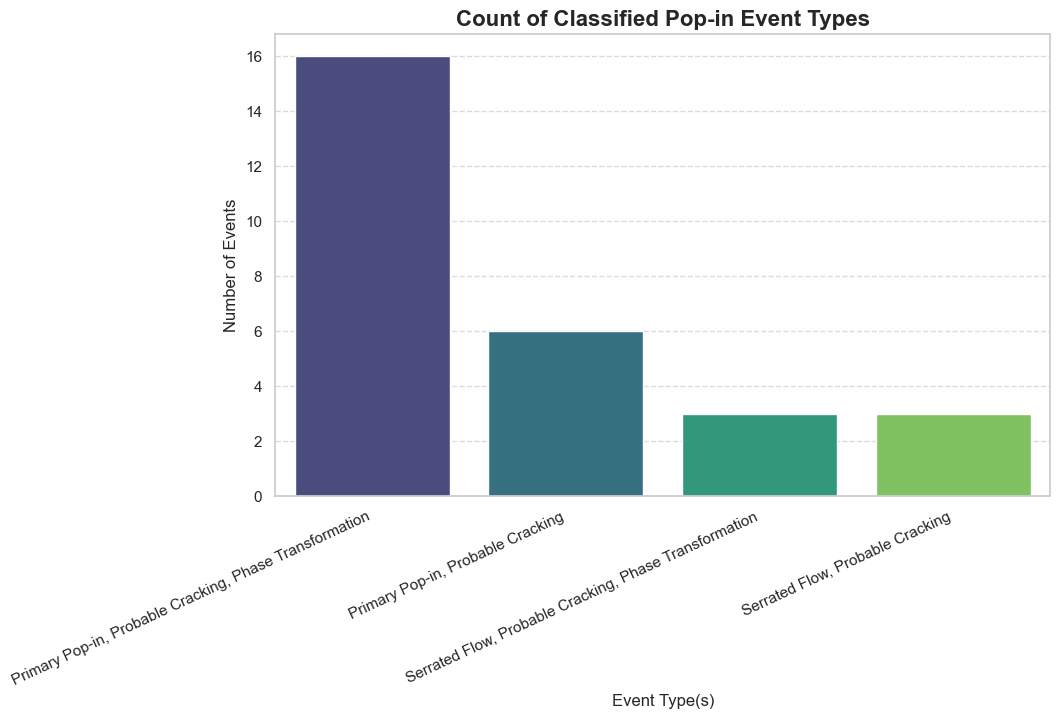

Example grid plot saved to 'popin_examples_grid.png'


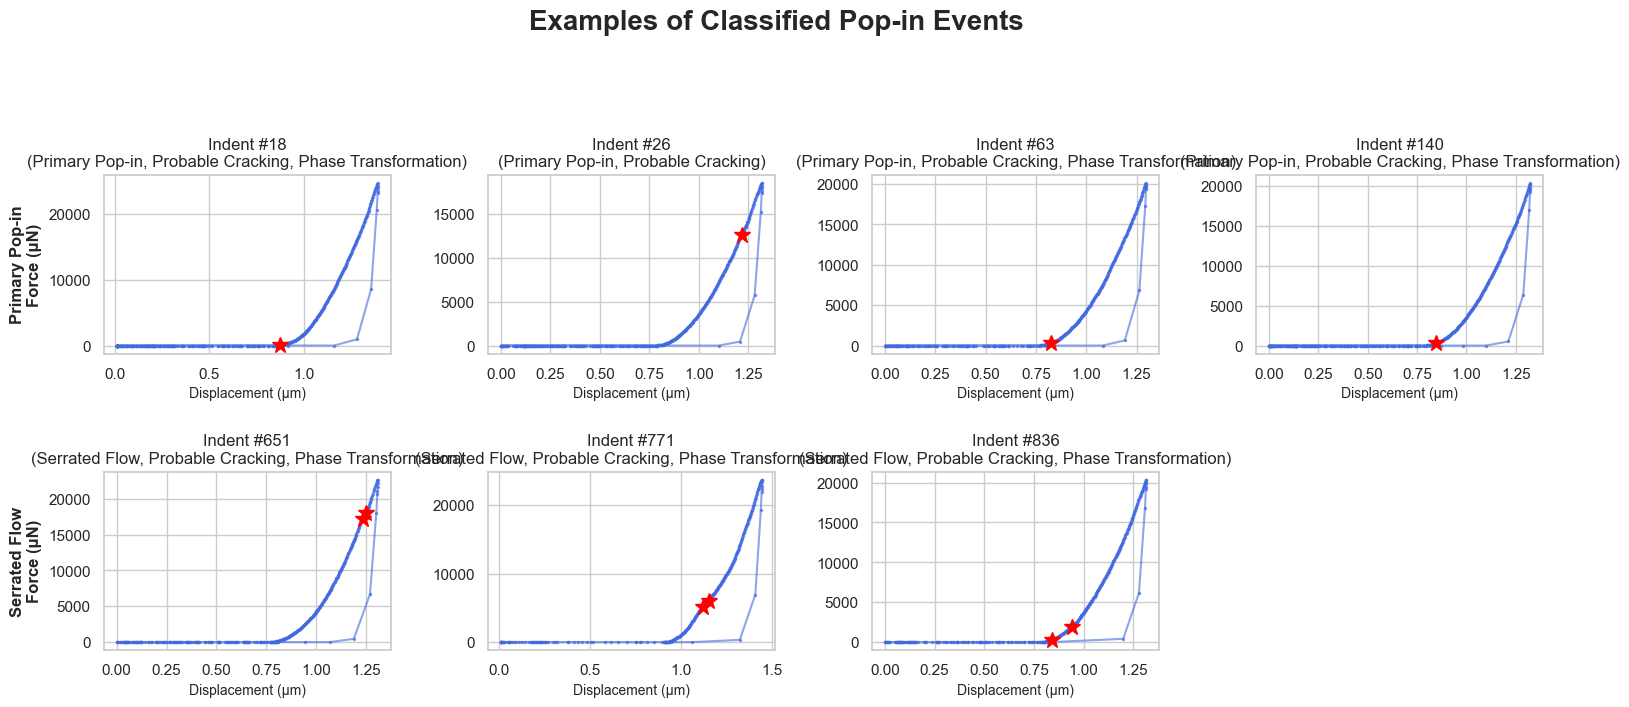


--- Final Summary Table (First 20 Events) ---
Full classified results saved to 'classified_popin_results.csv'
    Index                                     Event_Type_Str  Event_Num  \
0      18  Primary Pop-in, Probable Cracking, Phase Trans...          1   
1      26                  Primary Pop-in, Probable Cracking          1   
2      63  Primary Pop-in, Probable Cracking, Phase Trans...          1   
3     140  Primary Pop-in, Probable Cracking, Phase Trans...          1   
4     171  Primary Pop-in, Probable Cracking, Phase Trans...          1   
5     242                  Primary Pop-in, Probable Cracking          1   
6     342                  Primary Pop-in, Probable Cracking          1   
7     451  Primary Pop-in, Probable Cracking, Phase Trans...          1   
8     456  Primary Pop-in, Probable Cracking, Phase Trans...          1   
9     458  Primary Pop-in, Probable Cracking, Phase Trans...          1   
10    513                  Primary Pop-in, Probable Cracking    

In [44]:
## --- Step 6/6: Final Report and Visualization ---

import seaborn as sns
import matplotlib.pyplot as plt

print("--- Step 6: Generating Final Report and Visualizations ---")

if 'classified_df' not in locals() or classified_df.empty:
    print("Error: 'classified_df' is not available or is empty.")
    print("Please ensure Steps 4 and 5 ran successfully.")
else:
    # --- Visualization 1: Summary Bar Chart of Event Types ---
    plt.figure(figsize=(10, 6))
    
    # *** FIX: Changed 'Event_Type' to 'Event_Type_Str' ***
    sns.countplot(
        data=classified_df,
        x='Event_Type_Str',
        palette='viridis',
        order=classified_df['Event_Type_Str'].value_counts().index  # Sort by count
    )
    plt.title('Count of Classified Pop-in Event Types', fontsize=16, weight='bold')
    plt.xlabel('Event Type(s)', fontsize=12)
    plt.ylabel('Number of Events', fontsize=12)
    plt.xticks(rotation=25, ha='right') # Improved rotation for longer labels
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Save the summary chart
    summary_chart_path = 'popin_summary_chart.png'
    plt.savefig(summary_chart_path, bbox_inches='tight') # Use bbox_inches to prevent label cutoff
    print(f"\nSummary bar chart saved to '{summary_chart_path}'")
    plt.show()

    
    # --- Visualization 2: Example Plots for Each Event Type ---
    
    # *** FIX: Create 'Base_Type' from 'Event_Type_Str' ***
    # This helps group "Serrated Flow (Primary)" and "Serrated Flow (Secondary)"
    classified_df['Base_Type'] = classified_df['Event_Type_Str'].apply(
        lambda x: 'Serrated Flow' if 'Serrated Flow' in x else x.split(', ')[0]
    )
    event_types = classified_df['Base_Type'].unique()
    
    # Determine grid size (e.g., 4 examples per type)
    n_examples = 4
    n_cols = n_examples
    n_rows = len(event_types)
    
    if n_rows > 0:
        fig, axes = plt.subplots(
            n_rows,
            n_cols,
            figsize=(n_cols * 4, n_rows * 3.5),
            squeeze=False
        )
        fig.suptitle('Examples of Classified Pop-in Events', fontsize=20, weight='bold', y=1.03)

        for row_idx, event_type in enumerate(event_types):
            # Get up to 'n_examples' indices for this event type
            type_indices = classified_df[
                classified_df['Base_Type'] == event_type
            ]['Index'].unique()[:n_examples]
            
            axes[row_idx, 0].set_ylabel(f'{event_type}\nForce (μN)', fontsize=12, weight='bold')

            for col_idx, indent_index in enumerate(type_indices):
                ax = axes[row_idx, col_idx]
                
                # Get the raw data for this indent
                indent_data = raw_indent_groups.get(indent_index)
                if indent_data is None:
                    continue
                
                # Plot the full raw curve
                ax.plot(
                    indent_data['Displacement_um'],
                    indent_data['Force_uN'],
                    marker='.',
                    ms=3,
                    linestyle='-',
                    color='royalblue',
                    alpha=0.6,
                    label='Raw Data'
                )
                
                # Get all classified pop-ins for *this* indent
                events_on_this_indent = classified_df[classified_df['Index'] == indent_index]
                
                # Highlight each one with a red star
                ax.plot(
                    events_on_this_indent['Popin_Disp_um'],
                    events_on_this_indent['Popin_Force_uN'],
                    '*',
                    color='red',
                    markersize=12,
                    label='Pop-in(s)'
                )
                
                # Get the full classification string for this indent's first event
                full_label = events_on_this_indent.iloc[0]['Event_Type_Str']
                
                # Add a title for each plot
                ax.set_title(f'Indent #{indent_index}\n({full_label})', fontsize=12)
                ax.set_xlabel('Displacement (μm)', fontsize=10)
                if col_idx > 0:
                     ax.set_ylabel('') # Only label y-axis on the first plot of the row

                ax.grid(True)
                
            # If we have fewer than n_examples, hide the remaining axes
            for col_idx_empty in range(len(type_indices), n_cols):
                axes[row_idx, col_idx_empty].axis('off')

        
        plt.tight_layout(pad=2.0, rect=[0, 0, 1, 0.98])
        
        # Save the example grid
        example_chart_path = 'popin_examples_grid.png'
        plt.savefig(example_chart_path, bbox_inches='tight') # Use bbox_inches to prevent label cutoff
        print(f"Example grid plot saved to '{example_chart_path}'")
        plt.show()

    else:
        print("No classified events to plot in the grid.")
        
    print("\n--- Final Summary Table (First 20 Events) ---")
    # Save the final results to a CSV file for analysis
    results_csv_path = 'classified_popin_results.csv'
    
    # Select columns for the final report to make it cleaner
    report_columns = [
        'Index', 'Event_Type_Str', 'Event_Num', 'Total_Events', 
        'Popin_Force_uN', 'Popin_Disp_um', 'Stiffness_dF_dD', 'Has_PopOut'
    ]
    classified_df[report_columns].to_csv(results_csv_path, index=False)
    
    print(f"Full classified results saved to '{results_csv_path}'")
    print(classified_df[report_columns])

## **Function code**

Data loaded successfully! Found 999 indents.
Analyzing 999 indents...

--- Detection Summary ---
Found 25 indents with potential pop-in events.
Classifying events...
Classification complete.

--- Event Type Summary ---
Event_Type_Str
Primary Pop-in, Probable Cracking, Phase Transformation    16
Primary Pop-in, Probable Cracking                           6
Serrated Flow, Probable Cracking, Phase Transformation      3
Serrated Flow, Probable Cracking                            3
Name: count, dtype: int64

--- Final Summary Table (First 20 Events) ---
    Index                                     Event_Type_Str  Event_Num  \
0      18  Primary Pop-in, Probable Cracking, Phase Trans...          1   
1      26                  Primary Pop-in, Probable Cracking          1   
2      63  Primary Pop-in, Probable Cracking, Phase Trans...          1   
3     140  Primary Pop-in, Probable Cracking, Phase Trans...          1   
4     171  Primary Pop-in, Probable Cracking, Phase Trans...          

C:\Users\Hanamanthagouda\AppData\Local\Temp\ipykernel_21168\3139210007.py:73: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(filename, comment='/', delim_whitespace=True, header=None)


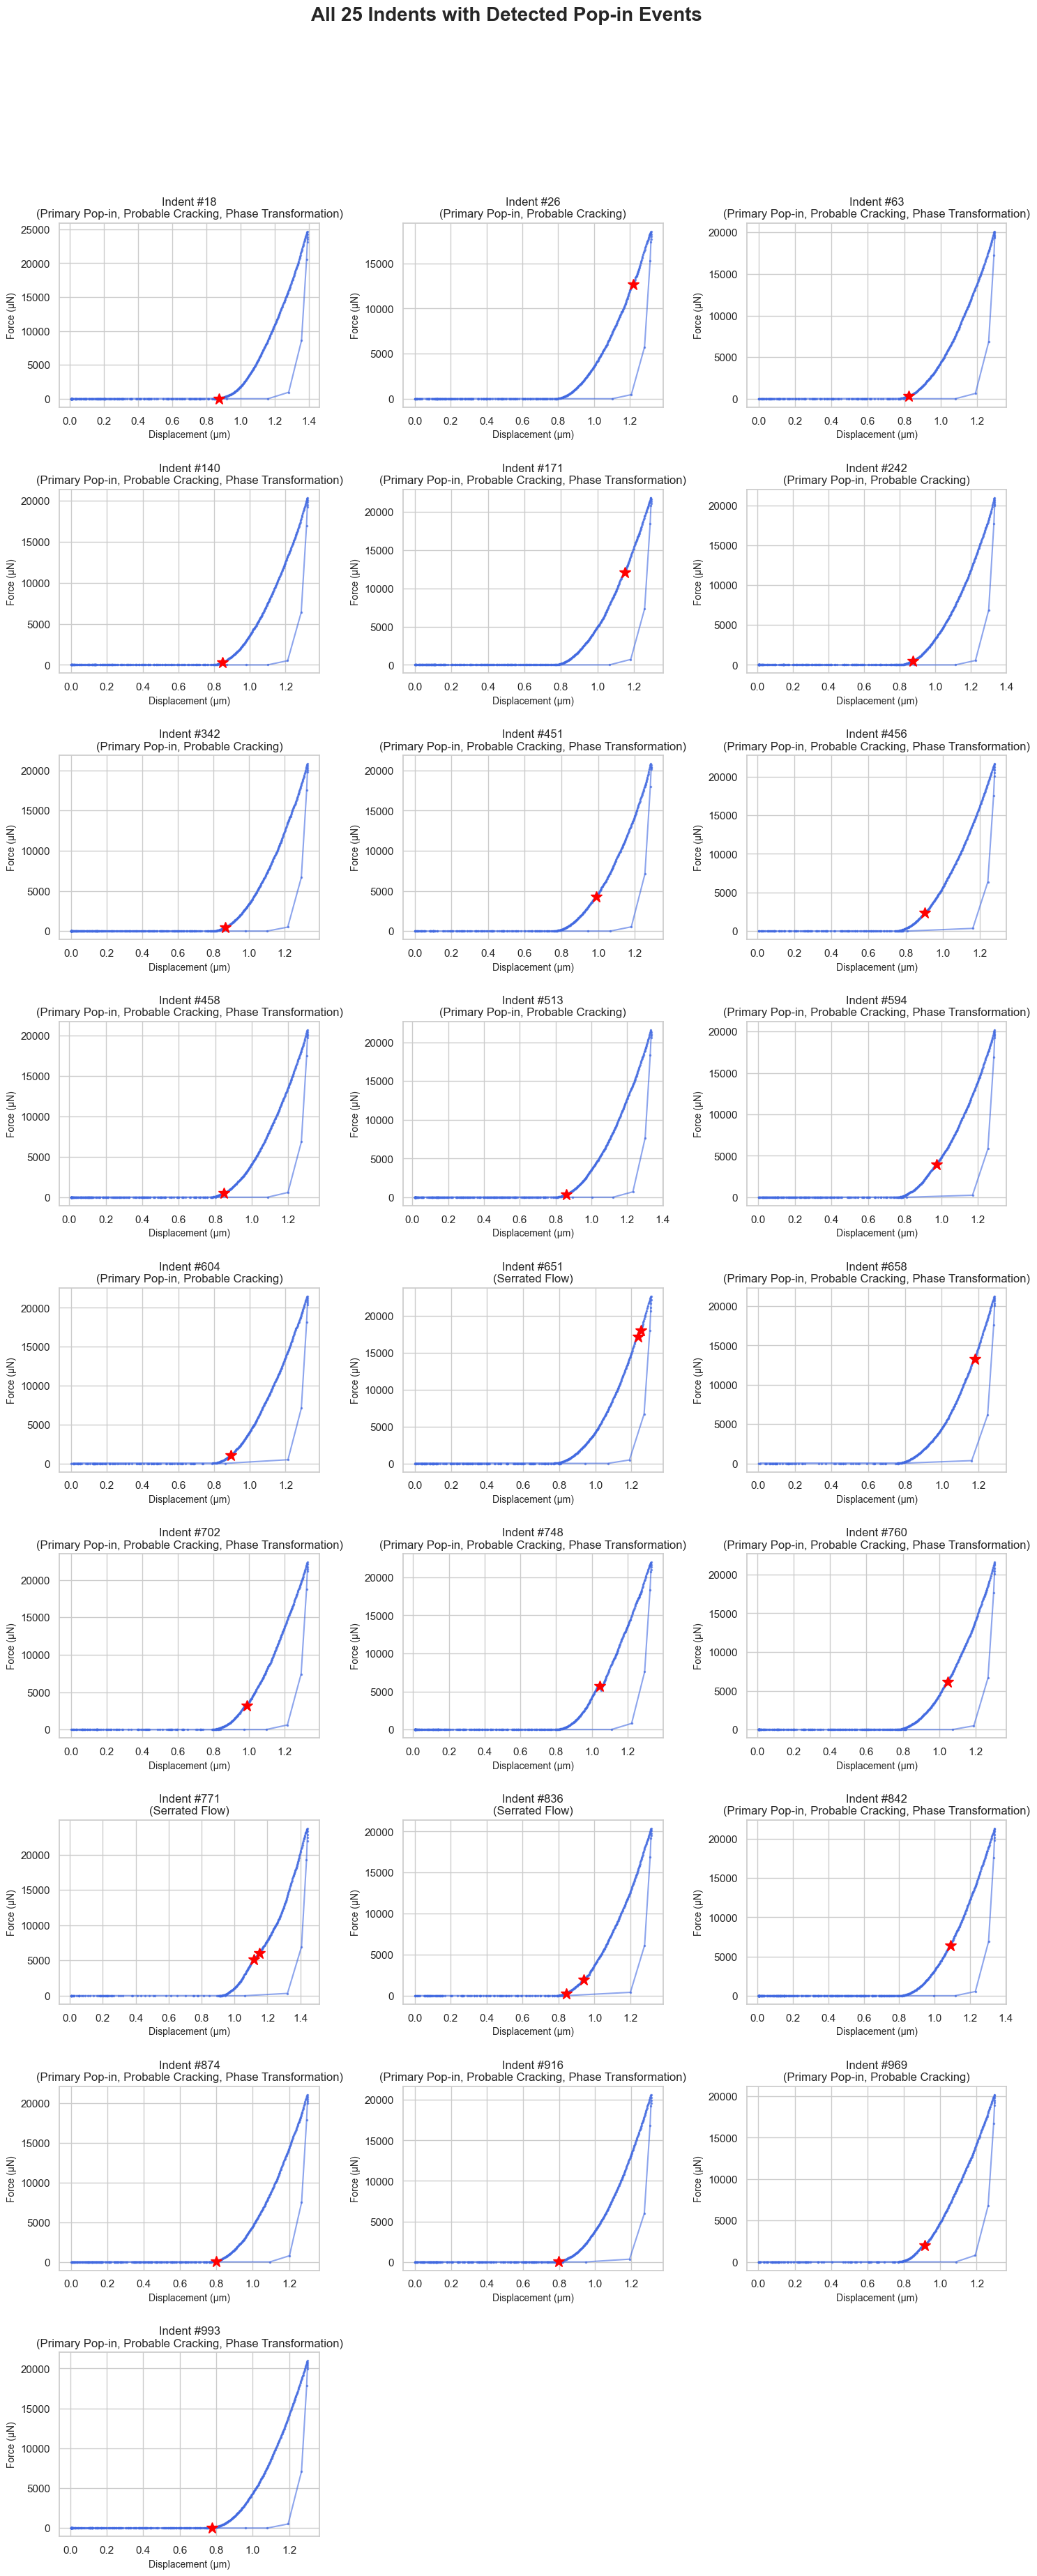

In [47]:
## --- Final Pop-in Analysis Script ---

import pandas as pd
import numpy as np
from scipy.signal import savgol_filter, find_peaks
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import math

def set_analysis_parameters():
    """
    Defines all user-configurable parameters for the pop-in analysis.
    Edit the values in this dictionary to tune the algorithm.
    """
    
    # --- File Parameters ---
    FILE_NAME = 'nano.txt'
    COLUMN_NAMES = {
        0: 'Index',
        2: 'Displacement_um',
        5: 'PosX_um',
        6: 'PosY_um',
        10: 'Force_uN',
        29: 'Hardness_MPa',
        30: 'ReducedModulus_MPa'
    }
    RESULTS_CSV_PATH = 'classified_popin_results.csv'

    # --- Pop-in Detection Parameters ---
    SLOPE_THRESHOLD = 10  # (uN / um) - "flatness" detector
    MIN_FORCE_FOR_DETECTION_uN = 25 # (uN) - Ignores noise at start
    MIN_CONSECUTIVE_POINTS = 1      # Robustness filter (1 = most sensitive)
    
    # --- Classification Parameters ---
    CRACKING_SLOPE_THRESHOLD = -50  # (uN / um) - "load drop" detector
    SAVGOL_WINDOW = 11
    SAVGOL_POLY = 2
    
    # Stricter Pop-out detection parameters (for phase change)
    POPOUT_PEAK_HEIGHT = 5.0
    POPOUT_PEAK_PROMINENCE = 5.0

    # --- Internal Parameters ---
    EPSILON = 1e-9 # To prevent divide-by-zero errors

    params = {
        "FILE_NAME": FILE_NAME,
        "COLUMN_NAMES": COLUMN_NAMES,
        "RESULTS_CSV_PATH": RESULTS_CSV_PATH,
        "SLOPE_THRESHOLD": SLOPE_THRESHOLD,
        "MIN_FORCE_FOR_DETECTION_uN": MIN_FORCE_FOR_DETECTION_uN,
        "MIN_CONSECUTIVE_POINTS": MIN_CONSECUTIVE_POINTS,
        "CRACKING_SLOPE_THRESHOLD": CRACKING_SLOPE_THRESHOLD,
        "SAVGOL_WINDOW": SAVGOL_WINDOW,
        "SAVGOL_POLY": SAVGOL_POLY,
        "POPOUT_PEAK_HEIGHT": POPOUT_PEAK_HEIGHT,
        "POPOUT_PEAK_PROMINENCE": POPOUT_PEAK_PROMINENCE,
        "EPSILON": EPSILON
    }
    
    return params


def run_pop_in_analysis(params):
    """
    Main function to run the complete analysis from file loading to visualization.
    """
    
    # --- Internal Helper Function: Load Data ---
    def _load_and_clean_data(filename, column_mapping):
        try:
            df = pd.read_csv(filename, comment='/', delim_whitespace=True, header=None)
            df = df[column_mapping.keys()].rename(columns=column_mapping)
            df['Index'] = df['Index'].astype(int)
            df.dropna(inplace=True)
            df = df[(df['Force_uN'] >= 0) & (df['Displacement_um'] >= 0)]
            print(f"Data loaded successfully! Found {df['Index'].nunique()} indents.")
            return df
        except FileNotFoundError:
            print(f"Error: '{filename}' not found.", file=sys.stderr)
            return None
        except Exception as e:
            print(f"An error occurred during loading: {e}", file=sys.stderr)
            return None

    # --- Internal Helper Function: Find Pop-Outs (Unloading) ---
    def _get_unloading_popout(indent_data, params):
        if indent_data.shape[0] < params["SAVGOL_WINDOW"]: return []
        try:
            max_force_idx = indent_data['Force_uN'].idxmax()
            unloading_data = indent_data.loc[max_force_idx:].copy().iloc[::-1]
        except ValueError: return []
        if unloading_data.shape[0] < params["SAVGOL_WINDOW"]: return []
        try:
            disp_smooth = savgol_filter(unloading_data['Displacement_um'], params["SAVGOL_WINDOW"], params["SAVGOL_POLY"])
            force_smooth = savgol_filter(unloading_data['Force_uN'], params["SAVGOL_WINDOW"], params["SAVGOL_POLY"])
        except ValueError: return []
        
        delta_disp = np.diff(disp_smooth)
        delta_force = np.diff(force_smooth)
        dD_dF_unload = delta_disp / (np.abs(delta_force) + params["EPSILON"])
        dD_dF_unload = np.insert(dD_dF_unload, 0, 0)
        dD_dF_unload[np.isinf(dD_dF_unload)] = 0
        
        popout_indices, _ = find_peaks(dD_dF_unload, height=params["POPOUT_PEAK_HEIGHT"], prominence=params["POPOUT_PEAK_PROMINENCE"])
        return popout_indices.tolist()

    # --- 1. Load Data ---
    df = _load_and_clean_data(params["FILE_NAME"], params["COLUMN_NAMES"])
    if df is None:
        return

    raw_indent_groups = {idx: group_df for idx, group_df in df.groupby('Index')}
    popin_analysis_results = []
    prepared_loading_data = {}

    # --- 2. Find Pop-in Candidates (Step 4) ---
    print(f"Analyzing {df['Index'].nunique()} indents...")
    for index, indent_data in raw_indent_groups.items():
        try:
            max_force_idx = indent_data['Force_uN'].idxmax()
            loading_data = indent_data.loc[:max_force_idx].copy()
        except ValueError: continue
        
        if loading_data.shape[0] < params["MIN_CONSECUTIVE_POINTS"] + 1: continue

        delta_force = np.diff(loading_data['Force_uN'])
        delta_disp = np.diff(loading_data['Displacement_um'])
        slope = delta_force / (delta_disp + params["EPSILON"])
        loading_data['Slope_dF_dD'] = np.insert(slope, 0, np.inf)

        is_flat = loading_data['Slope_dF_dD'] < params["SLOPE_THRESHOLD"]
        is_above_min_force = loading_data['Force_uN'] > params["MIN_FORCE_FOR_DETECTION_uN"]
        is_popin_candidate = is_flat & is_above_min_force

        consecutive_count = 0
        peak_indices_found = []
        for i, is_candidate in enumerate(is_popin_candidate):
            if is_candidate:
                consecutive_count += 1
            else:
                if consecutive_count >= params["MIN_CONSECUTIVE_POINTS"]:
                    peak_indices_found.append(loading_data.index[i - consecutive_count])
                consecutive_count = 0
        if consecutive_count >= params["MIN_CONSECUTIVE_POINTS"]:
            peak_indices_found.append(loading_data.index[len(loading_data) - consecutive_count])

        if peak_indices_found:
            popin_analysis_results.append({'Index': index, 'Peak_Indices': peak_indices_found, 'Peak_Count': len(peak_indices_found)})
            prepared_loading_data[index] = loading_data

    indents_with_popins = popin_analysis_results
    popin_count = len(indents_with_popins)
    popin_indices_list = sorted([res['Index'] for res in indents_with_popins])

    print(f"\n--- Detection Summary ---")
    print(f"Found {popin_count} indents with potential pop-in events.")
    if popin_count == 0:
        print("No events found. You may need to adjust your parameters.")
        return

    # --- 3. Characterization and Classification (Step 5) ---
    print("Classifying events...")
    classified_popin_events = []

    for popin_info in indents_with_popins:
        indent_index = popin_info['Index']
        peak_count = popin_info['Peak_Count']
        loading_data = prepared_loading_data.get(indent_index)
        raw_data = raw_indent_groups.get(indent_index)
        if loading_data is None: continue

        is_phase_change = len(_get_unloading_popout(raw_data, params)) > 0
        
        for i, peak_idx in enumerate(popin_info['Peak_Indices']):
            if peak_idx not in loading_data.index: continue
            
            event_types_list = []
            stiffness = loading_data.loc[peak_idx, 'Slope_dF_dD']

            if peak_count == 1: event_types_list.append("Primary Pop-in")
            else: event_types_list.append("Serrated Flow")
            
            if stiffness < params["CRACKING_SLOPE_THRESHOLD"]: event_types_list.append("Probable Cracking")
            if is_phase_change and i == 0: event_types_list.append("Phase Transformation")

            classified_popin_events.append({
                'Index': indent_index,
                'Event_Type_Str': ", ".join(event_types_list),
                'Event_Num': i + 1,
                'Total_Events': peak_count,
                'Popin_Force_uN': loading_data.loc[peak_idx, 'Force_uN'],
                'Popin_Disp_um': loading_data.loc[peak_idx, 'Displacement_um'],
                'Stiffness_dF_dD': stiffness,
                'Has_PopOut': is_phase_change
            })

    classified_df = pd.DataFrame(classified_popin_events)

    # --- 4. Final Report & Visualization (Step 6) ---
    print("Classification complete.")
    
    # Save the final results to a CSV file
    report_columns = [
        'Index', 'Event_Type_Str', 'Event_Num', 'Total_Events', 
        'Popin_Force_uN', 'Popin_Disp_um', 'Stiffness_dF_dD', 'Has_PopOut'
    ]
    final_report_df = classified_df[[col for col in report_columns if col in classified_df.columns]]
    final_report_df.to_csv(params["RESULTS_CSV_PATH"], index=False)
    
    print("\n--- Event Type Summary ---")
    print(final_report_df['Event_Type_Str'].value_counts())
    
    print("\n--- Final Summary Table (First 20 Events) ---")
    print(final_report_df.head(20))
    print(f"\nFull report saved to '{params['RESULTS_CSV_PATH']}'")

    # --- NEW: Plotting Grid (as requested) ---
    print("\nGenerating plots for all detected pop-in events...")
    sns.set_theme(style="whitegrid", palette="viridis") # Ensure styles are set
    
    unique_popin_indices = final_report_df['Index'].unique()
    n_cols = 3
    n_rows = math.ceil(len(unique_popin_indices) / n_cols)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4), squeeze=False)
    flat_axes = axes.flatten()

    for i, indent_index in enumerate(unique_popin_indices):
        ax = flat_axes[i]
        
        # Get raw data
        indent_data = raw_indent_groups.get(indent_index)
        if indent_data is None: continue
        
        # Plot the full raw curve
        ax.plot(
            indent_data['Displacement_um'],
            indent_data['Force_uN'],
            marker='.', ms=3, linestyle='-',
            color='royalblue', alpha=0.6, label='Raw Data'
        )
        
        # Get all classified pop-ins for this indent
        events_on_this_indent = final_report_df[final_report_df['Index'] == indent_index]
        
        # Highlight each one with a red star
        ax.plot(
            events_on_this_indent['Popin_Disp_um'],
            events_on_this_indent['Popin_Force_uN'],
            '*', color='red', markersize=12, label='Pop-in(s)'
        )
        
        # Get the full classification string for this indent
        full_label = events_on_this_indent['Event_Type_Str'].iloc[0]
        if events_on_this_indent['Total_Events'].iloc[0] > 1:
            full_label = "Serrated Flow" # Simplify title for serrated
        
        ax.set_title(f'Indent #{indent_index}\n({full_label})', fontsize=12)
        ax.set_xlabel('Displacement (μm)', fontsize=10)
        ax.set_ylabel('Force (μN)', fontsize=10)
        ax.grid(True)

    # Hide any unused subplots
    for j in range(i + 1, n_rows * n_cols):
        flat_axes[j].axis('off')

    fig.suptitle(f'All {len(unique_popin_indices)} Indents with Detected Pop-in Events', fontsize=20, weight='bold', y=1.03)
    plt.tight_layout(pad=2.0, rect=[0, 0, 1, 0.98])
    plt.show()
    
    return final_report_df

# --- Main execution block ---
# To run this, you would create a new cell and call:
#
analysis_params = set_analysis_parameters()
results_df = run_pop_in_analysis(analysis_params)
#

In [11]:
import pandas as pd
import numpy as np
from scipy.signal import savgol_filter, find_peaks
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import math

def set_analysis_parameters():
    """
    Defines all user-configurable parameters for the pop-in analysis.
    Edit the values in this dictionary to tune the algorithm.
    """
    
    # --- File Parameters ---
    FILE_NAME = 'nano.txt'
    COLUMN_NAMES = {
        0: 'Index',
        2: 'Displacement_um',
        5: 'PosX_um',
        6: 'PosY_um',
        10: 'Force_uN',
        29: 'Hardness_MPa',
        30: 'ReducedModulus_MPa'
    }
    RESULTS_CSV_PATH = 'classified_popin_results.csv'

    # --- Pop-in Detection Parameters ---
    SLOPE_THRESHOLD = 10  # (uN / um) - "flatness" detector
    MIN_FORCE_FOR_DETECTION_uN = 25 # (uN) - Ignores noise at start
    MIN_CONSECUTIVE_POINTS = 1 # Robustness filter (1 = most sensitive)
    
    # --- Classification Parameters ---
    CRACKING_SLOPE_THRESHOLD = -50 # (uN / um) - "load drop" detector
    SAVGOL_WINDOW = 11
    SAVGOL_POLY = 2
    
    # Stricter Pop-out detection parameters (for phase change)
    POPOUT_PEAK_HEIGHT = 5.0
    POPOUT_PEAK_PROMINENCE = 5.0

    # --- Internal Parameters ---
    EPSILON = 1e-9 # To prevent divide-by-zero errors

    params = {
        "FILE_NAME": FILE_NAME,
        "COLUMN_NAMES": COLUMN_NAMES,
        "RESULTS_CSV_PATH": RESULTS_CSV_PATH,
        "SLOPE_THRESHOLD": SLOPE_THRESHOLD,
        "MIN_FORCE_FOR_DETECTION_uN": MIN_FORCE_FOR_DETECTION_uN,
        "MIN_CONSECUTIVE_POINTS": MIN_CONSECUTIVE_POINTS,
        "CRACKING_SLOPE_THRESHOLD": CRACKING_SLOPE_THRESHOLD,
        "SAVGOL_WINDOW": SAVGOL_WINDOW,
        "SAVGOL_POLY": SAVGOL_POLY,
        "POPOUT_PEAK_HEIGHT": POPOUT_PEAK_HEIGHT,
        "POPOUT_PEAK_PROMINENCE": POPOUT_PEAK_PROMINENCE,
        "EPSILON": EPSILON
    }
    
    return params


def _load_and_clean_data(filename, column_mapping):
    """Internal helper to load and clean the raw nanoindentation data."""
    try:
        # Assuming fixed-width or space-delimited format based on original code
        df = pd.read_csv(filename, comment='/', delim_whitespace=True, header=None)
        df = df[column_mapping.keys()].rename(columns=column_mapping)
        df['Index'] = df['Index'].astype(int)
        df.dropna(inplace=True)
        # Ensure only positive data is considered
        df = df[(df['Force_uN'] >= 0) & (df['Displacement_um'] >= 0)] 
        print(f"Data loaded successfully! Found {df['Index'].nunique()} indents.")
        return df
    except FileNotFoundError:
        print(f"Error: '{filename}' not found. Please ensure the file is present.", file=sys.stderr)
        return None
    except Exception as e:
        print(f"An error occurred during loading: {e}", file=sys.stderr)
        return None

def _get_unloading_popout(indent_data, params):
    """Internal helper to detect pop-out events on the unloading curve (for phase change)."""
    if indent_data.shape[0] < params["SAVGOL_WINDOW"]: return []
    try:
        max_force_idx = indent_data['Force_uN'].idxmax()
        # Reverse the order for the unloading segment
        unloading_data = indent_data.loc[max_force_idx:].copy().iloc[::-1]
    except ValueError: return []
    
    if unloading_data.shape[0] < params["SAVGOL_WINDOW"]: return []
    
    try:
        # Smooth data for better derivative calculation
        disp_smooth = savgol_filter(unloading_data['Displacement_um'], params["SAVGOL_WINDOW"], params["SAVGOL_POLY"])
        force_smooth = savgol_filter(unloading_data['Force_uN'], params["SAVGOL_WINDOW"], params["SAVGOL_POLY"])
    except ValueError: return []
    
    # Calculate dD/dF (inverse stiffness) to find peaks during unloading
    delta_disp = np.diff(disp_smooth)
    delta_force = np.diff(force_smooth)
    dD_dF_unload = delta_disp / (np.abs(delta_force) + params["EPSILON"])
    dD_dF_unload = np.insert(dD_dF_unload, 0, 0)
    dD_dF_unload[np.isinf(dD_dF_unload)] = 0
    
    popout_indices, _ = find_peaks(dD_dF_unload, height=params["POPOUT_PEAK_HEIGHT"], prominence=params["POPOUT_PEAK_PROMINENCE"])
    return popout_indices.tolist()

def plot_validation_examples(raw_indent_groups, classified_df):
    """
    Generates three separate, maximized figures for the chosen validation indents.
    The pop-in event is indicated ONLY by a red arrow annotation with the predicted type,
    without a separate point marker.
    
    Args:
        raw_indent_groups (dict): Dictionary mapping index to raw data DataFrame.
        classified_df (pd.DataFrame): DataFrame containing all classified events.
    """
    
    # Indices chosen for presentation validation
    VALIDATION_INDICES = [26, 651, 748]
    
    # Set a clean, professional visual theme
    sns.set_theme(style="whitegrid", palette="deep") 

    for i, indent_index in enumerate(VALIDATION_INDICES):
        # --- CREATE A NEW FIGURE FOR EACH INDENT ---
        fig, ax = plt.subplots(figsize=(15, 10)) # Manually set a large size for each individual plot

        # 1. Get raw data
        indent_data = raw_indent_groups.get(indent_index)
        if indent_data is None: 
            ax.set_title(f'Indent #{indent_index} (Data Missing)')
            continue
        
        # 2. Get classified event data
        events_on_this_indent = classified_df[classified_df['Index'] == indent_index].sort_values(by='Popin_Disp_um')
        
        # 3. Plot the full raw curve
        ax.plot(
            indent_data['Displacement_um'],
            indent_data['Force_uN'],
            marker='', 
            linestyle='-', 
            linewidth=3.5, 
            color='#000080', 
            alpha=0.8, 
            label='Raw Data'
        )
        
        # Determine the full classification string for the label
        if events_on_this_indent.empty:
            full_label = "NO POP-IN DETECTED"
        elif events_on_this_indent['Total_Events'].iloc[0] > 1:
            full_label = "Serrated Flow / Multiple Events"
        else:
            full_label = events_on_this_indent['Event_Type_Str'].iloc[0]
        
        
        # 4. Highlight the first detected pop-in point and annotate (ARROW ONLY)
        if not events_on_this_indent.empty:
            first_event = events_on_this_indent.iloc[0]
            
            p_force = first_event['Popin_Force_uN']
            p_disp = first_event['Popin_Disp_um']
            
            # **REMOVED: ax.plot(p_disp, p_force, 'o', ...)**
            # The red dot marker is intentionally omitted as requested.
            
            # Add annotation (arrow and text) pointing directly to the pop-in point
            ax.annotate(full_label,
                        xy=(p_disp, p_force), 
                        # Adjust xytext to place the label near the point, slightly offset
                        xytext=(p_disp + 0.1, p_force + 400), 
                        arrowprops=dict(facecolor='red', 
                                        shrink=0.05, 
                                        width=5, 
                                        headwidth=15), 
                        fontsize=18, 
                        weight='bold',
                        color='red')

        
        # 5. Set titles and labels
        ax.set_title(f'Load-Displacement Curve for Indent #{indent_index} ({full_label})', 
                     fontsize=24, 
                     weight='bold') 
        ax.set_xlabel('Displacement ($\mu$m)', fontsize=20) 
        ax.set_ylabel('Force ($\mu$N)', fontsize=20) 
        ax.tick_params(axis='both', which='major', labelsize=14)
        ax.grid(True, linestyle='--', alpha=0.5)

        # Save each figure separately
        plot_filename = f'Validation_Popin_Indent_{indent_index}_Presentation_ArrowOnly.png'
        plt.tight_layout(pad=2.0) 
        plt.savefig(plot_filename, bbox_inches='tight')
        print(f"Validation plot saved to '{plot_filename}'")
        plt.close(fig) 

    print("\nAll validation plots generated successfully as separate files, using only the arrow for indication.")

# You must replace the existing plot_validation_examples function in your script with this revised version.    print("\nAll validation plots generated successfully as separate files.")    # plt.show() # Uncomment to display the plot directly

# Replace the existing function in your script with this one to generate the desired output.
def run_pop_in_analysis(params):
    """
    Main function to run the complete analysis from file loading to visualization.
    """
    
    # 1. Load Data
    df = _load_and_clean_data(params["FILE_NAME"], params["COLUMN_NAMES"])
    if df is None:
        return

    raw_indent_groups = {idx: group_df for idx, group_df in df.groupby('Index')}
    popin_analysis_results = []
    prepared_loading_data = {}

    # 2. Find Pop-in Candidates (Detection)
    print(f"Analyzing {df['Index'].nunique()} indents...")
    for index, indent_data in raw_indent_groups.items():
        try:
            max_force_idx = indent_data['Force_uN'].idxmax()
            loading_data = indent_data.loc[:max_force_idx].copy()
        except ValueError: continue
        
        if loading_data.shape[0] < params["MIN_CONSECUTIVE_POINTS"] + 1: continue

        delta_force = np.diff(loading_data['Force_uN'])
        delta_disp = np.diff(loading_data['Displacement_um'])
        # Calculate stiffness (dF/dD)
        slope = delta_force / (delta_disp + params["EPSILON"])
        loading_data['Slope_dF_dD'] = np.insert(slope, 0, np.inf)

        is_flat = loading_data['Slope_dF_dD'] < params["SLOPE_THRESHOLD"]
        is_above_min_force = loading_data['Force_uN'] > params["MIN_FORCE_FOR_DETECTION_uN"]
        is_popin_candidate = is_flat & is_above_min_force

        consecutive_count = 0
        peak_indices_found = []
        # Logic to group consecutive points into one event
        for i, is_candidate in enumerate(is_popin_candidate):
            if is_candidate:
                consecutive_count += 1
            else:
                if consecutive_count >= params["MIN_CONSECUTIVE_POINTS"]:
                    # Mark the beginning of the continuous low-stiffness segment
                    peak_indices_found.append(loading_data.index[i - consecutive_count])
                consecutive_count = 0
        if consecutive_count >= params["MIN_CONSECUTIVE_POINTS"]:
            peak_indices_found.append(loading_data.index[len(loading_data) - consecutive_count])

        if peak_indices_found:
            popin_analysis_results.append({'Index': index, 'Peak_Indices': peak_indices_found, 'Peak_Count': len(peak_indices_found)})
            prepared_loading_data[index] = loading_data

    indents_with_popins = popin_analysis_results
    popin_count = len(indents_with_popins)

    print(f"\n--- Detection Summary ---")
    print(f"Found {popin_count} indents with potential pop-in events.")
    if popin_count == 0:
        print("No events found. You may need to adjust your parameters.")
        return None, None

    # 3. Characterization and Classification
    print("Classifying events...")
    classified_popin_events = []

    for popin_info in indents_with_popins:
        indent_index = popin_info['Index']
        peak_count = popin_info['Peak_Count']
        loading_data = prepared_loading_data.get(indent_index)
        raw_data = raw_indent_groups.get(indent_index)
        if loading_data is None: continue

        # Check for phase change (pop-out)
        is_phase_change = len(_get_unloading_popout(raw_data, params)) > 0
        
        for i, peak_idx in enumerate(popin_info['Peak_Indices']):
            if peak_idx not in loading_data.index: continue
            
            event_types_list = []
            stiffness = loading_data.loc[peak_idx, 'Slope_dF_dD']

            # Primary classification based on event count
            if peak_count == 1: 
                event_types_list.append("Primary Pop-in")
            else: 
                event_types_list.append("Serrated Flow")
            
            # Secondary classification based on force/stiffness attributes
            if stiffness < params["CRACKING_SLOPE_THRESHOLD"]: 
                event_types_list.append("Probable Cracking")
            if is_phase_change and i == 0: 
                # Assuming phase transformation is visible during the first loading pop-in
                event_types_list.append("Phase Transformation")

            classified_popin_events.append({
                'Index': indent_index,
                'Event_Type_Str': ", ".join(event_types_list),
                'Event_Num': i + 1,
                'Total_Events': peak_count,
                'Popin_Force_uN': loading_data.loc[peak_idx, 'Force_uN'],
                'Popin_Disp_um': loading_data.loc[peak_idx, 'Displacement_um'],
                'Stiffness_dF_dD': stiffness,
                'Has_PopOut': is_phase_change
            })

    classified_df = pd.DataFrame(classified_popin_events)

    # 4. Final Report & Visualization
    print("Classification complete.")
    
    # Save the final results to a CSV file
    report_columns = [
        'Index', 'Event_Type_Str', 'Event_Num', 'Total_Events', 
        'Popin_Force_uN', 'Popin_Disp_um', 'Stiffness_dF_dD', 'Has_PopOut'
    ]
    final_report_df = classified_df[[col for col in report_columns if col in classified_df.columns]]
    final_report_df.to_csv(params["RESULTS_CSV_PATH"], index=False)
    
    print("\n--- Event Type Summary ---")
    print(final_report_df['Event_Type_Str'].value_counts())
    
    print("\n--- Final Summary Table (First 20 Events) ---")
    print(final_report_df.head(20))
    print(f"\nFull report saved to '{params['RESULTS_CSV_PATH']}'")
    
    return final_report_df, raw_indent_groups

# --- Main execution block ---
if __name__ == '__main__':
    analysis_params = set_analysis_parameters()
    
    # Run the analysis to get results and the raw data groups
    results_df, raw_data_groups = run_pop_in_analysis(analysis_params)

    # Only generate the validation plot if analysis was successful
    if results_df is not None and raw_data_groups is not None:
        plot_validation_examples(raw_data_groups, results_df)
    else:
        print("\nSkipping plot generation due to analysis failure or no events detected.")

C:\Users\Hanamanthagouda\AppData\Local\Temp\ipykernel_3284\3128985761.py:67: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(filename, comment='/', delim_whitespace=True, header=None)


Data loaded successfully! Found 999 indents.
Analyzing 999 indents...

--- Detection Summary ---
Found 25 indents with potential pop-in events.
Classifying events...
Classification complete.

--- Event Type Summary ---
Event_Type_Str
Primary Pop-in, Probable Cracking, Phase Transformation    16
Primary Pop-in, Probable Cracking                           6
Serrated Flow, Probable Cracking, Phase Transformation      3
Serrated Flow, Probable Cracking                            3
Name: count, dtype: int64

--- Final Summary Table (First 20 Events) ---
    Index                                     Event_Type_Str  Event_Num  \
0      18  Primary Pop-in, Probable Cracking, Phase Trans...          1   
1      26                  Primary Pop-in, Probable Cracking          1   
2      63  Primary Pop-in, Probable Cracking, Phase Trans...          1   
3     140  Primary Pop-in, Probable Cracking, Phase Trans...          1   
4     171  Primary Pop-in, Probable Cracking, Phase Trans...          

In [8]:
def plot_validation_examples(raw_indent_groups, classified_df):
    """
    Generates a single figure with three subplots for the chosen validation indents, 
    optimized for large, clear presentation quality.
    
    Args:
        raw_indent_groups (dict): Dictionary mapping index to raw data DataFrame.
        classified_df (pd.DataFrame): DataFrame containing all classified events.
    """
    
    # Indices chosen for presentation validation
    VALIDATION_INDICES = [26, 651, 748]
    
    # Set a clean, professional visual theme
    sns.set_theme(style="whitegrid", palette="deep") 
    
    # --- OPTIMIZED FIGURE SIZE for Presentation ---
    # Creates a 1x3 layout that is very wide and tall
    fig, axes = plt.subplots(1, 3, figsize=(27, 10), squeeze=False) 
    flat_axes = axes.flatten()

    # --- OPTIMIZED FONT SIZE for Main Title ---
    fig.suptitle('Validation of Automated Pop-in Classification', 
                 fontsize=30, # Increased
                 weight='bold', 
                 y=1.02) # Adjusted position

    for i, indent_index in enumerate(VALIDATION_INDICES):
        ax = flat_axes[i]
        
        # 1. Get raw data
        indent_data = raw_indent_groups.get(indent_index)
        if indent_data is None: 
            ax.set_title(f'Indent #{indent_index} (Data Missing)')
            continue
        
        # 2. Get classified event data
        # Focus on the first detected event for the annotation/label
        events_on_this_indent = classified_df[classified_df['Index'] == indent_index].sort_values(by='Popin_Disp_um')
        
        # 3. Plot the full raw curve
        ax.plot(
            indent_data['Displacement_um'],
            indent_data['Force_uN'],
            marker='', 
            linestyle='-', 
            linewidth=3.5, # Slightly thicker
            color='#000080', # Darker blue, similar to the attached image
            alpha=0.8, 
            label='Raw Data'
        )
        
        # Determine the full classification string for the label
        if events_on_this_indent.empty:
            full_label = "NO POP-IN DETECTED"
        elif events_on_this_indent['Total_Events'].iloc[0] > 1:
            full_label = "Serrated Flow / Multiple Events"
        else:
            full_label = events_on_this_indent['Event_Type_Str'].iloc[0]
        
        
        # 4. Highlight the first detected pop-in point and annotate
        if not events_on_this_indent.empty:
            first_event = events_on_this_indent.iloc[0]
            
            p_force = first_event['Popin_Force_uN']
            p_disp = first_event['Popin_Disp_um']
            
            # --- MAXIMIZED MARKER SIZE ---
            # Plot marker at the pop-in location
            ax.plot(p_disp, p_force, 'o', 
                    color='red', 
                    markersize=16, # Larger
                    markeredgecolor='black', # Add edge for visibility
                    zorder=5, 
                    label='Detected Event') 
            
            # Add annotation (arrow and text)
            # --- MAXIMIZED ARROW/HEAD WIDTH AND FONT SIZE ---
            ax.annotate(full_label,
                        xy=(p_disp, p_force), 
                        # Adjust text position for better visibility
                        xytext=(p_disp + 0.15, p_force + 250), 
                        arrowprops=dict(facecolor='red', 
                                        shrink=0.05, 
                                        width=5, # Thicker arrow
                                        headwidth=15), # Larger arrow head
                        fontsize=18, # Larger font size for the label
                        weight='bold',
                        color='red')

        
        # 5. Set titles and labels
        # --- MAXIMIZED FONT SIZES for Titles and Labels ---
        ax.set_title(f'Indent #{indent_index} ({full_label})', fontsize=24, weight='bold') # Added label to title
        ax.set_xlabel('Displacement ($\mu$m)', fontsize=20) 
        ax.set_ylabel('Force ($\mu$N)', fontsize=20) 
        ax.tick_params(axis='both', which='major', labelsize=14)
        ax.grid(True, linestyle='--', alpha=0.5)

    # Save the figure for presentation (and display it)
    plot_filename = 'Validation_Popin_Examples_26_651_748_Presentation.png'
    plt.tight_layout(pad=2.0, rect=[0, 0, 1, 0.98]) # Adjust rect for suptitle
    plt.savefig(plot_filename, bbox_inches='tight') # Use bbox_inches='tight' for better saving
    print(f"\nValidation plot saved to '{plot_filename}' with presentation-quality formatting.")
    # plt.show() # Uncomment to display the plot directly

# Replace the existing function in your script with this one to generate the desired output.